# Results: Problem 1

Test-set results from `src/problem1/main.py`. *default* = the classifier's own rule, *tuned* = threshold chosen on the validation set.

In [1]:
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Plot style: validated categorical palette, recessive grid and axes.
BLUE, ORANGE, AQUA = "#2a78d6", "#eb6834", "#1baf7a"
TEXT, TEXT_2, GRID = "#0b0b0b", "#52514e", "#e4e3df"
plt.rcParams.update({
    "figure.dpi": 110, "font.size": 10, "axes.edgecolor": TEXT_2, "axes.labelcolor": TEXT,
    "xtick.color": TEXT_2, "ytick.color": TEXT_2, "axes.spines.top": False,
    "axes.spines.right": False, "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.6,
    "axes.axisbelow": True, "legend.frameon": False, "axes.titlelocation": "left",
})
METRICS = ["precision", "recall", "f1"]
METRIC_COLORS = [BLUE, ORANGE, AQUA]

RESULTS = "../results/problem1/"
results = {
    "1e": pd.read_csv(RESULTS + "registry_results.csv"),
    "1f": pd.read_csv(RESULTS + "full_results.csv"),
    "1h": pd.read_csv(RESULTS + "bagging_results.csv"),
}
TITLES = {"1e": "(1e) Registry features", "1f": "(1f) Full features",
          "1h": "(1h) Bagging comparison"}
with open(RESULTS + "run_config.json") as f:
    config = json.load(f)

## 1. Data split

Split by site into 70% / 15% / 15%.

In [2]:
split = pd.DataFrame(config["split"]).T
split["positive_rate"] = split["positive_rate"].astype(float).round(3)
print("seed:", config["seed"])
split

seed: 2026


,sites,rows,positive_rate
train,347.0,2171.0,0.184
validation,74.0,462.0,0.193
test,75.0,483.0,0.207


## 2. Result tables

In [3]:
for key, df in results.items():
    print(TITLES[key])
    display(df[["model", "rule", "precision", "recall", "f1", "hyperparameters", "threshold"]]
            .round(3))

(1e) Registry features


,model,rule,precision,recall,f1,hyperparameters,threshold
0,Dummy (stratified),mean of 100 runs,0.208,0.185,0.196,"{""random_state"": ""2026-2125""}",NaN
1,Naive Bayes (Parzen),default,0.292,0.140,0.189,"{""bandwidth"": 0.1}",default
2,Naive Bayes (Parzen),tuned,0.285,0.450,0.349,"{""bandwidth"": 0.1}",0.1905
3,Least Squares,default,0.286,0.020,0.037,"{""reg_lambda"": 0.001}",default
4,Least Squares,tuned,0.230,0.650,0.340,"{""reg_lambda"": 0.001}",0.1810
5,MLP,default,0.000,0.000,0.000,"{""hidden_sizes"": [16], ""learning_rate"": 0.001,...",default
6,MLP,tuned,0.225,0.380,0.282,"{""hidden_sizes"": [16], ""learning_rate"": 0.001,...",0.2434


(1f) Full features


,model,rule,precision,recall,f1,hyperparameters,threshold
0,Dummy (stratified),mean of 100 runs,0.208,0.185,0.196,"{""random_state"": ""2026-2125""}",NaN
1,Naive Bayes (Parzen),default,0.318,0.140,0.194,"{""bandwidth"": 0.25}",default
2,Naive Bayes (Parzen),tuned,0.302,0.670,0.416,"{""bandwidth"": 0.25}",0.1489
3,Least Squares,default,0.000,0.000,0.000,"{""reg_lambda"": 10.0}",default
4,Least Squares,tuned,0.294,0.580,0.391,"{""reg_lambda"": 10.0}",0.1925
5,MLP,default,0.000,0.000,0.000,"{""hidden_sizes"": [32, 16], ""learning_rate"": 0....",default
6,MLP,tuned,0.267,0.620,0.374,"{""hidden_sizes"": [32, 16], ""learning_rate"": 0....",0.1872


(1h) Bagging comparison


,model,rule,precision,recall,f1,hyperparameters,threshold
0,Dummy (stratified),mean of 100 runs,0.208,0.185,0.196,"{""random_state"": ""2026-2125""}",NaN
1,Naive Bayes (Parzen),default,0.318,0.140,0.194,"{""bandwidth"": 0.25}",default
2,Naive Bayes (Parzen),tuned,0.302,0.670,0.416,"{""bandwidth"": 0.25}",0.1489
3,Least Squares,default,0.000,0.000,0.000,"{""reg_lambda"": 10.0}",default
4,Least Squares,tuned,0.294,0.580,0.391,"{""reg_lambda"": 10.0}",0.1925
5,MLP,default,0.000,0.000,0.000,"{""hidden_sizes"": [32, 16], ""learning_rate"": 0....",default
6,MLP,tuned,0.267,0.620,0.374,"{""hidden_sizes"": [32, 16], ""learning_rate"": 0....",0.1872
7,Bagged NB (Parzen),default,0.318,0.140,0.194,"{""bandwidth"": 0.25}",default
8,Bagged NB (Parzen),tuned,0.323,0.630,0.427,"{""bandwidth"": 0.25}",0.1834


## 3. Precision, recall and F1

Tuned threshold, with the dummy baseline.

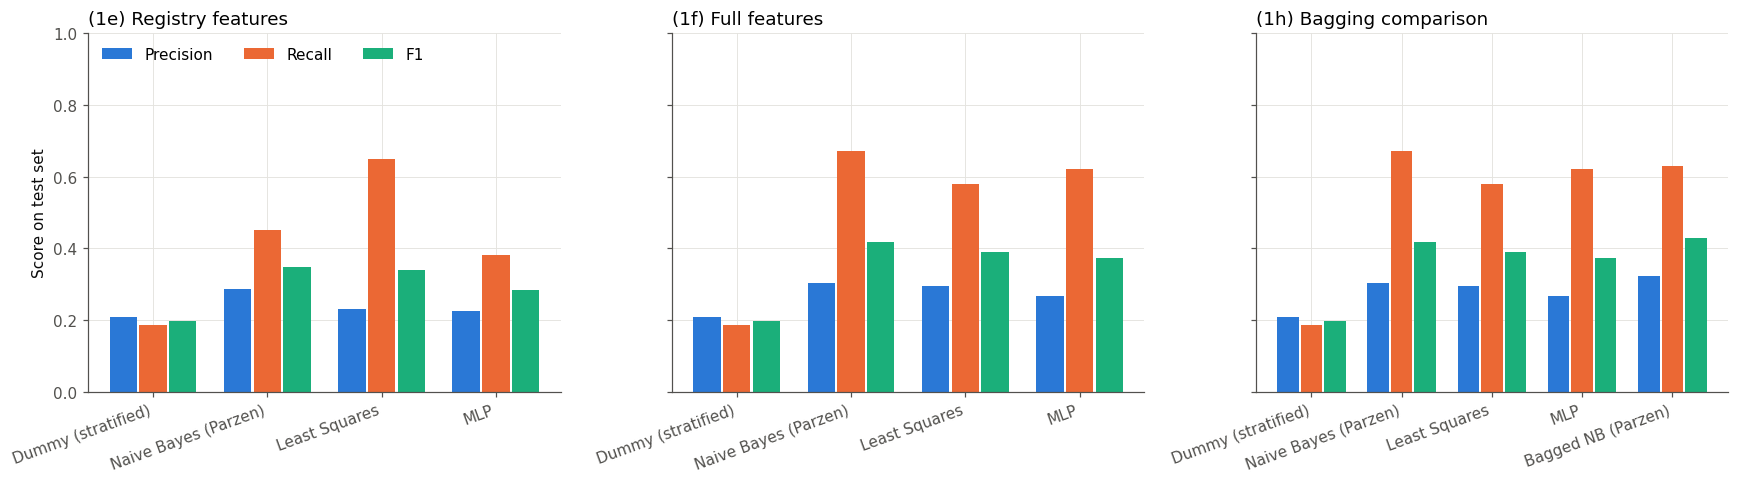

In [4]:
def table_for(df, rule):
    """Rows of the learned classifiers with `rule`, plus the dummy row."""
    keep = (df["rule"] == rule) | df["model"].str.startswith("Dummy")
    return df[keep].reset_index(drop=True)


def metric_bars(ax, df, title):
    x = np.arange(len(df))
    width = 0.26
    for j, (metric, color) in enumerate(zip(METRICS, METRIC_COLORS)):
        ax.bar(x + (j - 1) * width, df[metric], width * 0.92, color=color,
               label=metric.capitalize() if metric != "f1" else "F1")
    for i, row in df.iterrows():          # bars of height 0 are invisible -> label them
        if row[METRICS].max() == 0:
            ax.text(x[i], 0.02, "all 0", ha="center", va="bottom", color=TEXT_2, fontsize=8)
    ax.set_xticks(x)
    ax.set_xticklabels(df["model"], rotation=20, ha="right")
    ax.set_ylim(0, 1)
    ax.set_title(title)


fig, axes = plt.subplots(1, 3, figsize=(16, 4.5), sharey=True)
for ax, key in zip(axes, results):
    metric_bars(ax, table_for(results[key], "tuned"), TITLES[key])
axes[0].set_ylabel("Score on test set")
axes[0].legend(ncol=3, loc="upper left")
fig.tight_layout()

## 4. Default vs tuned threshold

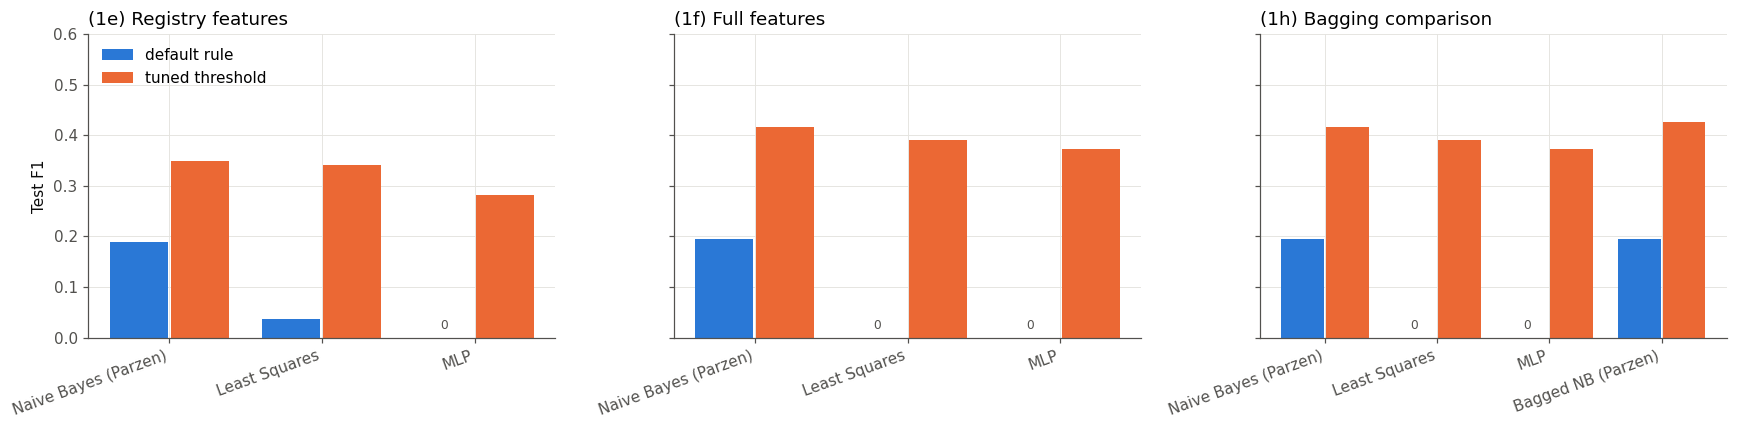

In [5]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4), sharey=True)
for ax, key in zip(axes, results):
    df = results[key]
    learned = df[~df["model"].str.startswith("Dummy")]
    models = learned["model"].unique()
    f1 = learned.pivot(index="model", columns="rule", values="f1").loc[models]
    x = np.arange(len(models))
    ax.bar(x - 0.2, f1["default"], 0.38, color=BLUE, label="default rule")
    ax.bar(x + 0.2, f1["tuned"], 0.38, color=ORANGE, label="tuned threshold")
    for i, v in enumerate(f1["default"]):
        if v == 0:
            ax.text(x[i] - 0.2, 0.01, "0", ha="center", va="bottom", color=TEXT_2, fontsize=8)
    ax.set_xticks(x); ax.set_xticklabels(models, rotation=20, ha="right")
    ax.set_ylim(0, 0.6); ax.set_title(TITLES[key])
axes[0].set_ylabel("Test F1")
axes[0].legend(loc="upper left")
fig.tight_layout()

## 5. Registry vs full features (1e vs 1f)

,Δ precision,Δ recall,Δ f1
model,,,
Naive Bayes (Parzen),0.017,0.22,0.067
Least Squares,0.064,-0.07,0.050
MLP,0.042,0.24,0.091


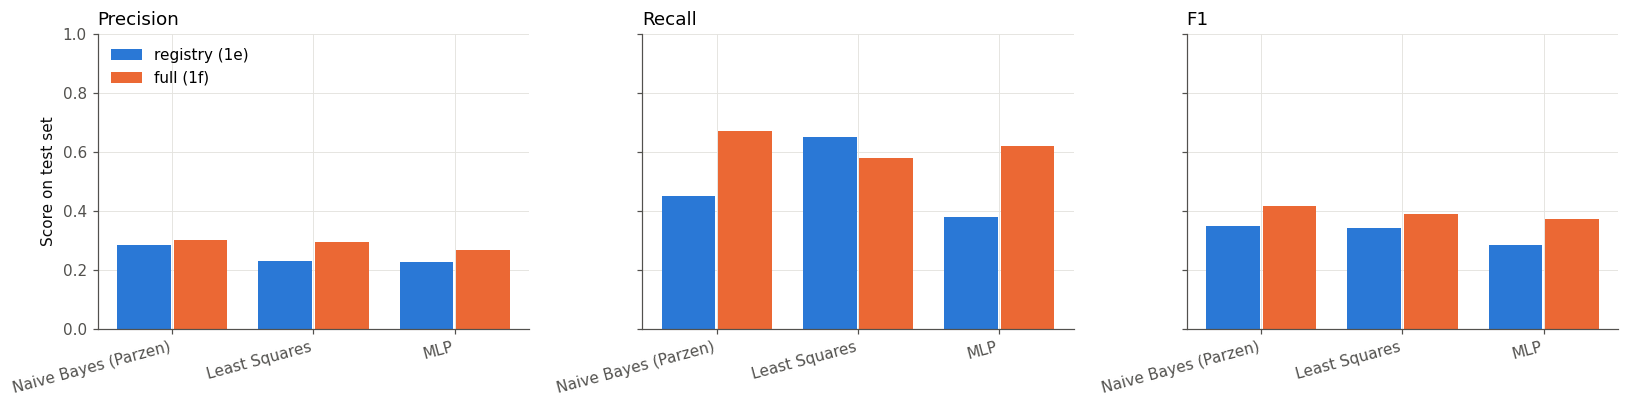

In [6]:
reg = table_for(results["1e"], "tuned").set_index("model")
full = table_for(results["1f"], "tuned").set_index("model")
models = [m for m in reg.index if not m.startswith("Dummy")]

fig, axes = plt.subplots(1, 3, figsize=(15, 3.8), sharey=True)
x = np.arange(len(models))
for ax, metric in zip(axes, METRICS):
    ax.bar(x - 0.2, reg.loc[models, metric], 0.38, color=BLUE, label="registry (1e)")
    ax.bar(x + 0.2, full.loc[models, metric], 0.38, color=ORANGE, label="full (1f)")
    ax.set_xticks(x); ax.set_xticklabels(models, rotation=15, ha="right")
    ax.set_title(metric.capitalize() if metric != "f1" else "F1")
    ax.set_ylim(0, 1)
axes[0].set_ylabel("Score on test set")
axes[0].legend(loc="upper left")
fig.tight_layout()

change = (full.loc[models, METRICS] - reg.loc[models, METRICS]).round(3)
change.columns = [f"Δ {m}" for m in METRICS]
change

## 6. Bagged vs unbagged naive Bayes (1h)

,model,rule,precision,recall,f1
1,Naive Bayes (Parzen),default,0.318,0.14,0.194
2,Naive Bayes (Parzen),tuned,0.302,0.67,0.416
7,Bagged NB (Parzen),default,0.318,0.14,0.194
8,Bagged NB (Parzen),tuned,0.323,0.63,0.427


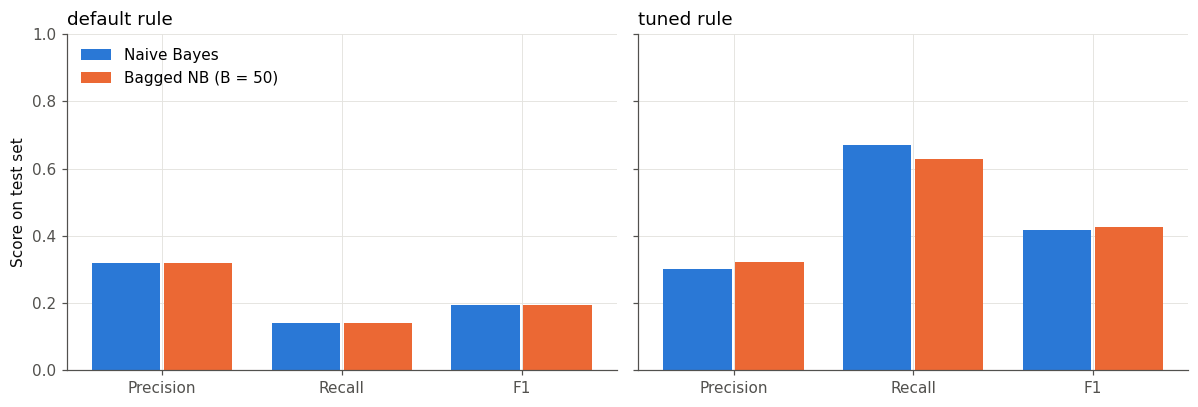

In [7]:
h = results["1h"]
nb_models = ["Naive Bayes (Parzen)", "Bagged NB (Parzen)"]

fig, axes = plt.subplots(1, 2, figsize=(11, 3.8), sharey=True)
for ax, rule in zip(axes, ["default", "tuned"]):
    sub = h[(h["rule"] == rule) & h["model"].isin(nb_models)].set_index("model").loc[nb_models]
    x = np.arange(len(METRICS))
    ax.bar(x - 0.2, sub.loc[nb_models[0], METRICS], 0.38, color=BLUE, label="Naive Bayes")
    ax.bar(x + 0.2, sub.loc[nb_models[1], METRICS], 0.38, color=ORANGE, label="Bagged NB (B = 50)")
    ax.set_xticks(x); ax.set_xticklabels(["Precision", "Recall", "F1"])
    ax.set_ylim(0, 1); ax.set_title(f"{rule} rule")
axes[0].set_ylabel("Score on test set")
axes[0].legend(loc="upper left")
fig.tight_layout()

h[h["model"].isin(nb_models)][["model", "rule", "precision", "recall", "f1"]].round(3)

## 7. Hyperparameter selection

Validation F1 of every hyperparameter setting.

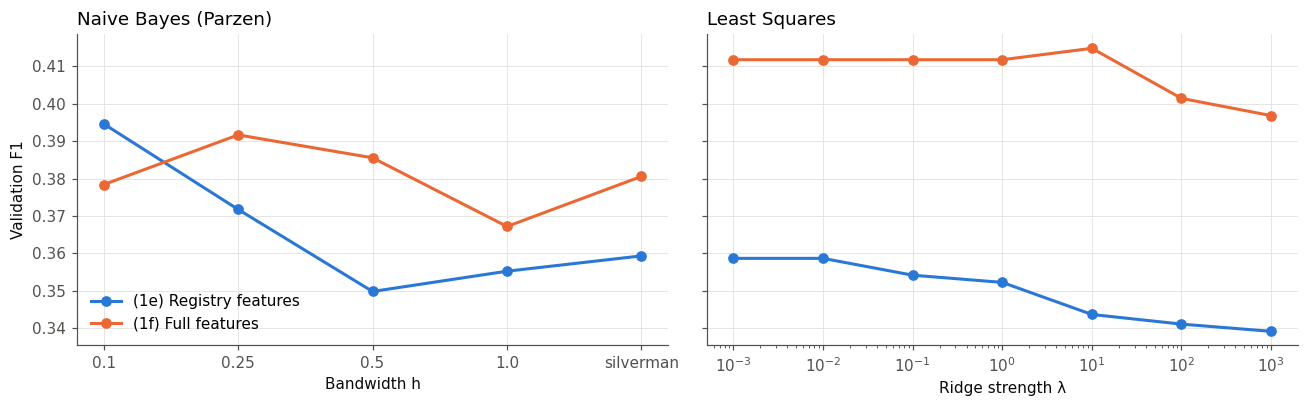

In [8]:
validation = config["validation"]
EXP_COLORS = {"(1e) Registry features": BLUE, "(1f) Full features": ORANGE}


def val_table(title, model):
    rows = validation[title][model]
    return pd.DataFrame([{**r["params"], "val_f1": r["val_f1_tuned"]} for r in rows])


fig, axes = plt.subplots(1, 2, figsize=(12, 3.8), sharey=True)

# Naive Bayes: bandwidth h (categorical axis, includes "silverman").
for title, color in EXP_COLORS.items():
    t = val_table(title, "Naive Bayes (Parzen)")
    axes[0].plot(t["bandwidth"].astype(str), t["val_f1"], color=color, lw=2,
                 marker="o", ms=6, label=title)
axes[0].set_xlabel("Bandwidth h"); axes[0].set_ylabel("Validation F1")
axes[0].set_title("Naive Bayes (Parzen)")
axes[0].legend(loc="lower left")

# Least squares: ridge strength λ (log axis).
for title, color in EXP_COLORS.items():
    t = val_table(title, "Least Squares")
    axes[1].plot(t["reg_lambda"], t["val_f1"], color=color, lw=2, marker="o", ms=6, label=title)
axes[1].set_xscale("log")
axes[1].set_xlabel("Ridge strength λ"); axes[1].set_title("Least Squares")
fig.tight_layout()

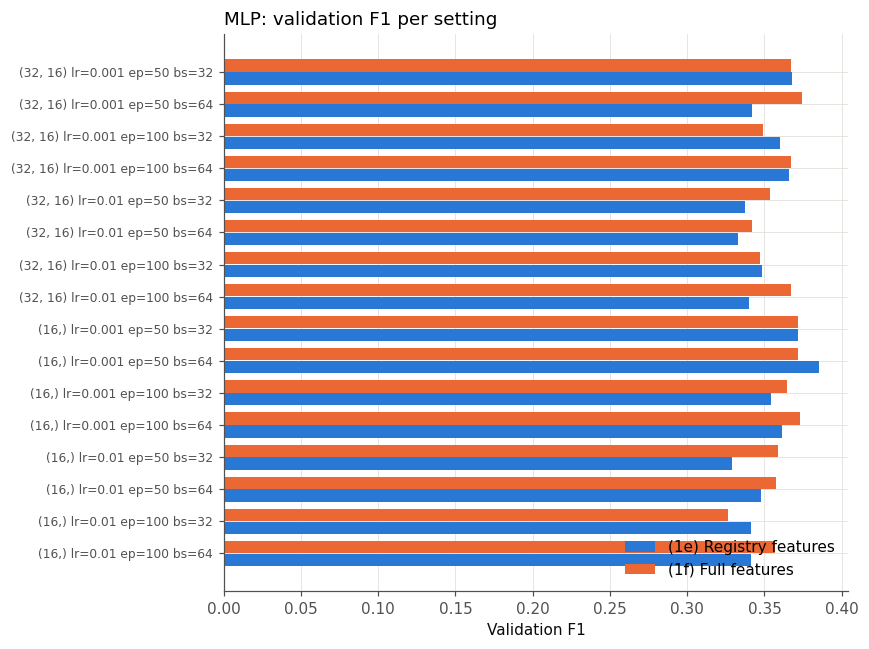

In [9]:
# MLP: 16 settings, one bar per setting and experiment.
t_e = val_table("(1e) Registry features", "MLP")
t_f = val_table("(1f) Full features", "MLP")
labels = [f"{tuple(r.hidden_sizes)} lr={r.learning_rate:g} ep={r.n_epochs} bs={r.batch_size}"
          for r in t_e.itertuples()]

fig, ax = plt.subplots(figsize=(8, 6))
yy = np.arange(len(labels))
ax.barh(yy + 0.2, t_e["val_f1"], 0.38, color=BLUE, label="(1e) Registry features")
ax.barh(yy - 0.2, t_f["val_f1"], 0.38, color=ORANGE, label="(1f) Full features")
ax.set_yticks(yy); ax.set_yticklabels(labels, fontsize=8)
ax.invert_yaxis()
ax.set_xlabel("Validation F1"); ax.set_title("MLP: validation F1 per setting")
ax.legend(loc="lower right")
fig.tight_layout()

In [10]:
# Selected hyperparameters and thresholds per experiment and classifier.
selected = []
for key, df in results.items():
    for r in df[df["rule"] == "tuned"].itertuples():
        selected.append({"experiment": key, "model": r.model,
                         "hyperparameters": r.hyperparameters, "threshold": r.threshold})
pd.DataFrame(selected)

,experiment,model,hyperparameters,threshold
0,1e,Naive Bayes (Parzen),"{""bandwidth"": 0.1}",0.1905
1,1e,Least Squares,"{""reg_lambda"": 0.001}",0.1810
2,1e,MLP,"{""hidden_sizes"": [16], ""learning_rate"": 0.001,...",0.2434
3,1f,Naive Bayes (Parzen),"{""bandwidth"": 0.25}",0.1489
4,1f,Least Squares,"{""reg_lambda"": 10.0}",0.1925
5,1f,MLP,"{""hidden_sizes"": [32, 16], ""learning_rate"": 0....",0.1872
6,1h,Naive Bayes (Parzen),"{""bandwidth"": 0.25}",0.1489
7,1h,Least Squares,"{""reg_lambda"": 10.0}",0.1925
8,1h,MLP,"{""hidden_sizes"": [32, 16], ""learning_rate"": 0....",0.1872
9,1h,Bagged NB (Parzen),"{""bandwidth"": 0.25}",0.1834
